# 7r_demotools_graduate: single years with `DemoTools::graduate`, Kumamoto

4r and 5r split the 5-year bands into single years of age with the penalized composite link model (`ungroup::pclm`, 1D or 2D). This notebook tries the classic graduation methods in **`DemoTools::graduate()`** (Riffe et al.) instead, for the 45 listed Kumamoto municipalities:

| `method` | What it does |
|---|---|
| `uniform` | spreads each band evenly over its 5 ages (a step function; the naive reference) |
| `sprague` | Sprague's fifth-difference osculatory interpolation (1880), fixed multipliers over neighbouring bands |
| `beers(ord)` | Beers' ordinary formula (1945): osculatory, reproduces band totals |
| `beers(mod)` | Beers' modified formula: smoother, totals only approximately kept |
| `grabill` | Grabill's formula: a smoothed Sprague |
| `mono` | monotone cubic spline through the cumulative counts (never negative) |

`pclm` is also a `graduate()` method, but it is the same ungroup model as 4r, so the reference here is 4r's own fit: **1D `pclm` with the national single-year shape as offset** for population and plain `pclm` for deaths (`output/4r_pclm_cache.qs2`).

**Setup**
- **Bands:** population and deaths are harmonised to 0–4 … 75–79, 80+ (the population's top band is 80+ up to 2014). The open 80+ band is kept as one group, so single ages are **0–79**. The residual is computed for ages 0–78 at the start of each interval (the cohort must still be under 80 a year later), for every method including the 4r reference.
- **`constrain = TRUE`:** every fit is rescaled to keep the published band totals. `graduate()` silently replaces negative values (possible with Sprague, Beers and Grabill in small or uneven counts) by the geometric mean with the `mono` fit; the table after the fits counts how often the raw split had negatives.
- **Window:** counts on 1 January 2014 … 2021 and deaths 2014–2020, so every interval is one calendar year and matches the migration report exactly.
- **Residual, Lexis rule, cohorts and groups:** as in 4r (sections 3 and 5): NM = P<sub>t+1</sub>(*x*+1) − P<sub>t</sub>(*x*) + ½·(D<sub>t</sub>(*x*) + D<sub>t</sub>(*x*+1)).
- **Reported side of the validation:** identical for all methods: (in − out) Japanese movers between municipalities, 1D `pclm` split from the 4r cache, same Lexis rule. Only the population and death splits differ.

**Figures**
- Figures 1–2: how each method splits population (2016-01-01) and deaths (2016) for 熊本市, 益城町 and 五木村.
- Figure 3: single-age residuals in the pre-quake years (method noise).
- Figure 4: residual vs reported net migration per method, laid out like 5r figure 11.
- Figure 5: SD of residual − reported by cohort and by municipality size, all methods (like 5r figure 3).

Figures are written to `res/7r_<NN>_<item>.png`. Run `4r_residual_migration.ipynb` first: this notebook reads its cache. `DemoTools` is installed from GitHub (pinned commit; see the Dockerfile).

In [1]:
suppressWarnings(suppressPackageStartupMessages({
  library(dplyr)
  library(tidyr)
  library(ggplot2)
  library(qs2)
  library(ungroup)
  library(DemoTools)
}))
options(repr.plot.width = 16, repr.plot.height = 9, repr.plot.res = 110,
        jupyter.plot_mimetypes = "image/png")

root <- if (dir.exists("dt")) "." else ".."
res_dir <- file.path(root, "res")
dir.create(res_dir, showWarnings = FALSE)
surface <- "#fcfcfb"
ink <- "#2b2b29"; ink2 <- "#5c5c58"; ink3 <- "#8a8a85"; grid_col <- "#e6e5e1"
jp_font <- "Noto Sans CJK JP"

nb_prefix <- "7r_"
show_save <- function(p, name, width = 16, height = 9) {
  ggsave(file.path(res_dir, paste0(nb_prefix, name, ".png")), p,
         width = width, height = height, dpi = 150, bg = surface)
  print(p)
  invisible(p)
}
top_age <- 105

base_theme <- function() list(
  theme_minimal(base_size = 10, base_family = jp_font),
  theme(
    plot.background = element_rect(fill = surface, colour = NA),
    panel.grid.minor = element_blank(),
    panel.grid.major.x = element_blank(),
    panel.grid.major.y = element_line(colour = grid_col, linewidth = 0.3),
    panel.spacing = unit(0.5, "cm"),
    strip.text = element_text(face = "bold", hjust = 0, colour = ink, size = 9.5),
    plot.title = element_text(face = "bold", size = 14),
    plot.subtitle = element_text(colour = ink2, size = 10),
    plot.caption = element_text(colour = ink3, size = 8, hjust = 0),
    plot.title.position = "plot",
    plot.caption.position = "plot",
    axis.text = element_text(colour = ink2, size = 8),
    axis.title = element_text(colour = ink2, size = 10),
    legend.position = "top",
    legend.justification = "left",
    legend.text = element_text(size = 10)
  )
)
src_note <- paste0("Population: Basic Resident Register (住民基本台帳), Japanese residents. Deaths: Vital Statistics (人口動態統計), ",
                   "Japanese, by residence. Net migration = residual (population change + deaths).")

# One entry per disaster: population count years (labels as in the 住基 data),
# baseline count and the quake interval (identified by its starting count).
events <- list(
  tohoku   = list(title = "2011 Great East Japan Earthquake", groups = c("東日本", "福島"),
                  counts = 2006:2016, base = 2010, quake_start = 2010),
  kumamoto = list(title = "2016 Kumamoto Earthquake", groups = "熊本",
                  counts = 2011:2021, base = 2016, quake_start = 2016)
)

In [2]:
study <- readxl::read_excel(file.path(root, "dt/analysis_original_data.xlsx"),
                            sheet = "1_市町村一覧", col_types = "text") |>
  filter(災害 == "熊本") |>
  transmute(code = 市町村コード, muni = 市町村, short = sub("^.*郡", "", 市町村),
            zenkai_rate = as.numeric(`全壊率(全壊棟数/人口×100)`)) |>
  mutate(group = case_when(zenkai_rate >= 1 ~ "High damage (全壊率 ≥ 1)",
                           code == "43100" ~ "熊本市",
                           TRUE ~ "Other listed (Kumamoto)"))
group_levels <- c("High damage (全壊率 ≥ 1)", "熊本市", "Other listed (Kumamoto)")
group_cols <- setNames(c("#eb6834", "#2a78d6", "#1baf7a"), group_levels)

counts <- 2014:2021; death_years <- 2014:2020; base <- 2016
to80 <- function(b) ifelse(b %in% c("80_84", "85_89", "90+", "90_94", "95_99", "100+", "80+"), "80+", b)
harmonise <- function(d) {   # 0-4 ... 75-79, 80+ per code x year
  d |> filter(!age_band %in% c("total", "unknown")) |>
    group_by(code, year) |> filter(!(age_band == "80+" & any(age_band == "80_84"))) |> ungroup() |>
    mutate(band = to80(age_band)) |>
    group_by(code, year, band) |> summarise(n = sum(n), .groups = "drop") |>
    mutate(lower = as.integer(sub("[_+].*", "", band)))
}
pop5 <- qs_read(file.path(root, "dt/jumin_age_sex_5yr_long.qs2")) |>
  filter(code %in% study$code, basis == "japanese", sex == "計", year %in% counts) |>
  transmute(code, year, age_band = as.character(age_band), n = pop) |> harmonise()
dth5 <- qs_read(file.path(root, "dt/deaths_age_sex_5yr_long.qs2")) |>
  filter(code %in% study$code, sex == "計", year %in% death_years) |>
  transmute(code, year, age_band = as.character(age_band), n) |> harmonise()

cache1d <- file.path(root, "output/4r_pclm_cache.qs2")
if (!file.exists(cache1d)) stop("Run src/4r_residual_migration.ipynb first: it writes ", cache1d)
fits1d <- qs_read(cache1d) |> filter(code %in% study$code)

bind_rows(pop5 |> mutate(series = "population"), dth5 |> mutate(series = "deaths")) |>
  group_by(series) |>
  summarise(municipalities = n_distinct(code), years = paste(range(year), collapse = "–"),
            bands = n_distinct(band), zero_bands = sum(n == 0), total = sum(n), .groups = "drop") |>
  as.data.frame()

series,municipalities,years,bands,zero_bands,total
<chr>,<int>,<chr>,<int>,<int>,<dbl>
deaths,45,2014–2020,17,2308,148323
population,45,2014–2021,17,0,14245079


## 1. Graduating every municipality and year

One `graduate()` call per municipality × year × series × method: 45 × (8 counts + 7 death years) × 6 methods = 4,050 fits. They take a few seconds, so nothing is cached.

In [3]:
methods <- c("uniform", "sprague", "beers(ord)", "beers(mod)", "grabill", "mono")
ref_lab <- "pclm + national offset (4r)"
method_levels <- c(methods, ref_lab)
method_cols <- setNames(c("#b5b4af", "#2a78d6", "#1baf7a", "#8a5cc2", "#e3a21a", "#eb6834", "#2b2b29"), method_levels)

# graduate() on one set of harmonised bands; returns ages 0-79 (80 = the open band, dropped).
# graduate() silently replaces negative values (geometric mean with the mono fit), so the
# raw osculatory split is computed separately to record whether that happened.
raw_split <- function(lower, n, method) switch(method,
  "sprague"    = graduate_sprague(n, Age = lower, OAG = TRUE),
  "beers(ord)" = graduate_beers(n, Age = lower, OAG = TRUE, method = "ord"),
  "beers(mod)" = graduate_beers(n, Age = lower, OAG = TRUE, method = "mod"),
  "grabill"    = graduate_grabill(n, Age = lower, OAG = TRUE),
  NULL)
grad_one <- function(lower, n, method) {
  raw <- raw_split(lower, n, method)
  out <- graduate(Value = n, Age = lower, OAG = TRUE, method = method, constrain = TRUE)
  tibble(age = seq_along(out) - 1, fit = unname(out), negative_fixed = !is.null(raw) && any(raw < 0)) |>
    filter(age < 80)
}
t0 <- Sys.time()
gfits <- bind_rows(pop5 |> mutate(series = "pop"), dth5 |> mutate(series = "deaths")) |>
  arrange(code, series, year, lower) |>
  group_by(code, series, year) |>
  group_modify(function(g, k) bind_rows(lapply(methods, function(m) grad_one(g$lower, g$n, m) |> mutate(method = m)))) |>
  ungroup()
message("graduate fits: ", n_distinct(paste(gfits$code, gfits$series, gfits$year, gfits$method)),
        " in ", round(as.numeric(difftime(Sys.time(), t0, units = "secs"))), " s")

# 4r reference, cut to ages 0-79 like the others
rfits <- fits1d |> filter(series %in% c("pop", "deaths"), age < 80,
                          (series == "pop" & year %in% counts) | (series == "deaths" & year %in% death_years)) |>
  transmute(code, series, year, age, fit, negative_fixed = FALSE, method = ref_lab)
allfits <- bind_rows(gfits, rfits) |> mutate(method = factor(method, levels = method_levels))

# Checks: band totals kept (ages 0-79), negative values replaced, smallest single-age value
band_tot <- bind_rows(pop5 |> mutate(series = "pop"), dth5 |> mutate(series = "deaths")) |>
  filter(lower < 80) |> group_by(code, series, year) |> summarise(published = sum(n), .groups = "drop")
allfits |> group_by(code, series, year, method) |>
  summarise(fitted = sum(fit), neg = any(negative_fixed), min_fit = min(fit), .groups = "drop") |>
  left_join(band_tot, by = c("code", "series", "year")) |>
  group_by(series, method) |>
  summarise(fits = n(), max_abs_total_diff = signif(max(abs(fitted - published)), 2),
            fits_with_negatives_fixed = sum(neg), min_single_age = round(min(min_fit), 2), .groups = "drop") |>
  as.data.frame()

graduate fits: 4050 in 5 s



series,method,fits,max_abs_total_diff,fits_with_negatives_fixed,min_single_age
<chr>,<fct>,<int>,<dbl>,<int>,<dbl>
deaths,uniform,315,5.7e-14,0,0.00
deaths,sprague,315,0.0e+00,312,0.00
deaths,beers(ord),315,1.8e-15,313,0.00
deaths,beers(mod),315,0.0e+00,307,0.00
deaths,grabill,315,5.7e-14,301,0.00
deaths,mono,315,3.6e-15,0,0.00
deaths,pclm + national offset (4r),315,5.7e-14,0,0.00
pop,uniform,360,0.0e+00,0,3.20
pop,sprague,360,0.0e+00,0,0.40


## 2. What the splits look like (figures 1–2)

Three listed municipalities of very different size: 熊本市 (~730k), 益城町 (~33k Japanese residents) and 五木村 (~1.2k). Bars are the published 5-year bands drawn as counts per single year (band ÷ 5); lines are the single-year splits. All methods keep every band total (to rounding), so they differ only inside the bands.

- **Population (figure 1):** the classic formulas pass a smooth curve through neighbouring bands; they know nothing about the national cohort cliffs (1945–46 vs 1947–49 births at ages 66–70, 1966 at age 49), which only the 4r offset fit puts in.
- **Deaths (figure 2):** a few dozen deaths a year in the village, with many empty bands. The raw Sprague, Beers and Grabill splits go negative next to empty bands in almost every municipality-year (table above); `graduate()` patches those ages with the `mono` fit.

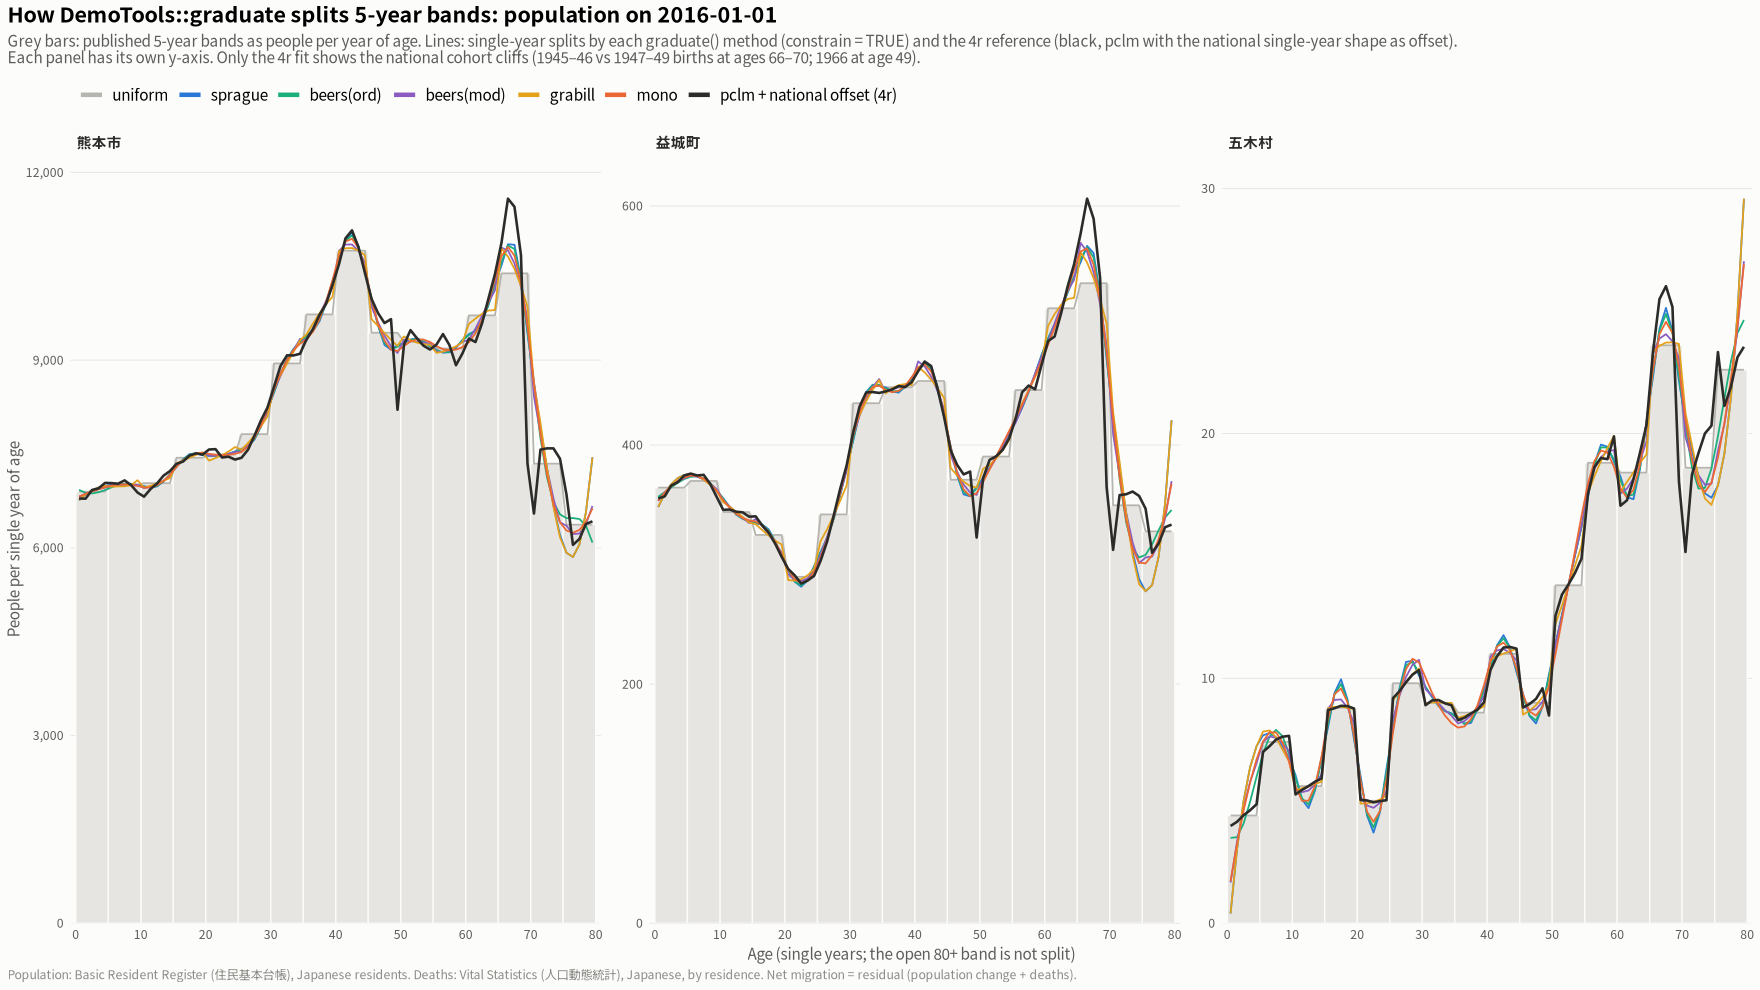

In [4]:
show3 <- study |> filter(short %in% c("熊本市", "益城町", "五木村")) |>
  mutate(short = factor(short, levels = c("熊本市", "益城町", "五木村")))
plot_split <- function(ser, yr, src5, title, subtitle, ylab) {
  bars <- src5 |> filter(code %in% show3$code, year == yr, lower < 80) |>
    mutate(per_year = n / 5) |> left_join(show3 |> select(code, short), by = "code")
  lines <- allfits |> filter(series == ser, year == yr, code %in% show3$code) |>
    left_join(show3 |> select(code, short), by = "code")
  ggplot() +
    geom_rect(data = bars, aes(xmin = lower, xmax = lower + 5, ymin = 0, ymax = per_year),
              fill = "#e6e5e1", colour = surface, linewidth = 0.4) +
    geom_line(data = lines, aes(age + 0.5, fit, colour = method, linewidth = method == ref_lab)) +
    facet_wrap(~short, ncol = 3, scales = "free_y") +
    scale_colour_manual(values = method_cols, name = NULL) +
    scale_linewidth_manual(values = c(`FALSE` = 0.55, `TRUE` = 0.8), guide = "none") +
    scale_x_continuous(breaks = seq(0, 80, 10), expand = expansion(mult = 0.01)) +
    scale_y_continuous(labels = scales::label_comma(), expand = expansion(mult = c(0, 0.06))) +
    labs(title = title, subtitle = subtitle, x = "Age (single years; the open 80+ band is not split)", y = ylab, caption = src_note) +
    base_theme() +
    guides(colour = guide_legend(nrow = 1, override.aes = list(linewidth = 1.4)))
}
show_save(plot_split("pop", base, pop5,
  "How DemoTools::graduate splits 5-year bands: population on 2016-01-01",
  paste0("Grey bars: published 5-year bands as people per year of age. Lines: single-year splits by each graduate() method (constrain = TRUE) ",
         "and the 4r reference (black, pclm with the national single-year shape as offset).\nEach panel has its own y-axis. ",
         "Only the 4r fit shows the national cohort cliffs (1945–46 vs 1947–49 births at ages 66–70; 1966 at age 49)."),
  "People per single year of age"), "01_population_splits", width = 17, height = 6.5)

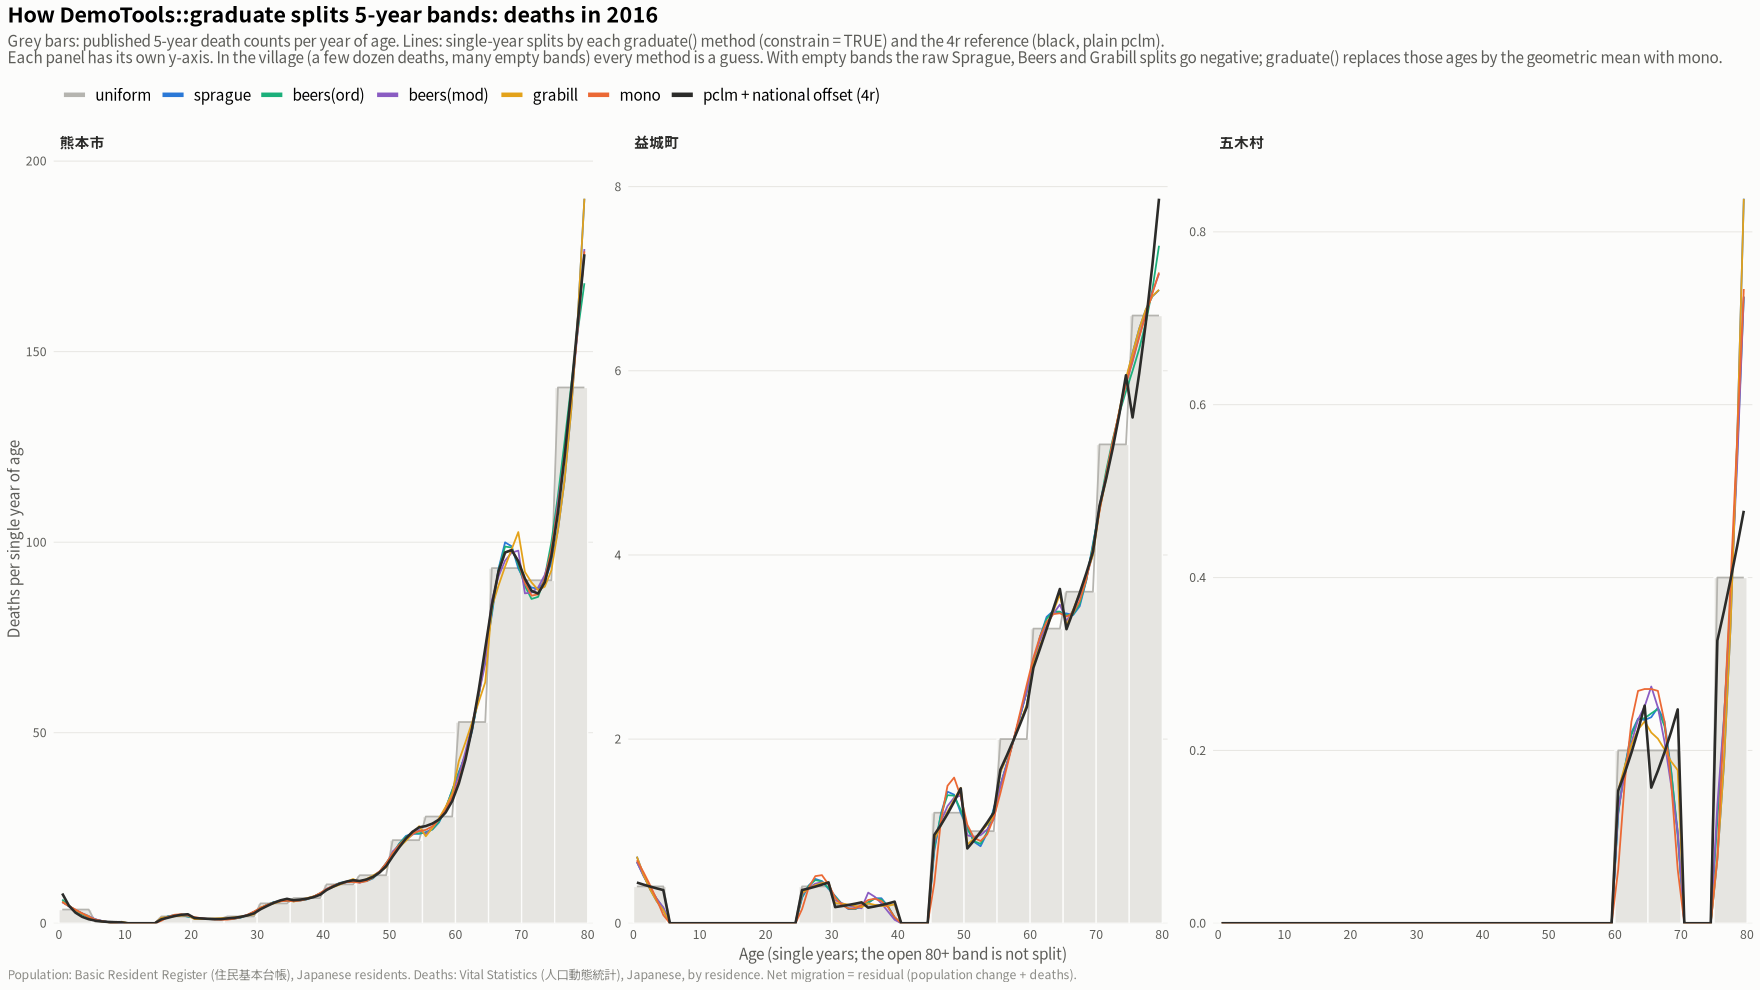

In [5]:
show_save(plot_split("deaths", base, dth5,
  "How DemoTools::graduate splits 5-year bands: deaths in 2016",
  paste0("Grey bars: published 5-year death counts per year of age. Lines: single-year splits by each graduate() method (constrain = TRUE) ",
         "and the 4r reference (black, plain pclm).\nEach panel has its own y-axis. In the village (a few dozen deaths, many empty bands) every method is a guess. ",
         "With empty bands the raw Sprague, Beers and Grabill splits go negative; graduate() replaces those ages by the geometric mean with mono."),
  "Deaths per single year of age"), "02_death_splits", width = 17, height = 6.5)

## 3. Residual net migration with each split

The residual as in 4r, computed separately for every method's population and death splits, for single ages 0–78 at the start of each interval. Cohorts are labelled by their age on 2016-01-01 (the baseline); 2014 and 2015 are the back-cast.

**Totals differ by method, and that is expected.** Summed over ages 0–78, the residual is (end population at ages 1–79) − (start population at ages 0–78) + deaths. Band totals are the same for every method, so the sum depends on the split only through two single ages: **age 0 at the end** (newborns, who belong to no starting cohort) and **age 79 at the start** (the cohort that leaves the range). The table shows how much these two edge ages move the total; it says nothing about the cohorts inside the range, which section 4 checks.

In [6]:
cohort_bins <- c(paste0(seq(0, 35, 5), "–", seq(4, 39, 5)), "40–49", "50–59", "60–69", "70–78")
cohort_of <- function(a0) {
  lab <- case_when(a0 < 40 ~ paste0(a0 %/% 5 * 5, "–", a0 %/% 5 * 5 + 4),
                   a0 < 70 ~ paste0(a0 %/% 10 * 10, "–", a0 %/% 10 * 10 + 9),
                   a0 <= 78 ~ "70–78", TRUE ~ NA_character_)
  factor(lab, levels = cohort_bins)
}
residual_of <- function(m) {
  P <- allfits |> filter(method == m, series == "pop") |> select(code, count = year, age, P = fit)
  D <- allfits |> filter(method == m, series == "deaths") |> select(code, start = year, age, D = fit) |>
    group_by(code, start) |> arrange(age, .by_group = TRUE) |>
    mutate(Dc = 0.5 * (D + lead(D, default = 0))) |> ungroup()
  P |> rename(start = count, P0 = P) |>
    filter(start %in% death_years, age <= 78) |>
    inner_join(P |> transmute(code, start = count - 1, age = age - 1, P1 = P), by = c("code", "start", "age")) |>
    inner_join(D |> select(code, start, age, Dc), by = c("code", "start", "age")) |>
    mutate(NM = P1 - P0 + Dc, method = m)
}
res <- bind_rows(lapply(method_levels, residual_of)) |>
  left_join(study |> select(code, short, group), by = "code") |>
  mutate(method = factor(method, levels = method_levels),
         group = factor(group, levels = group_levels),
         a0 = age - (start - base), cohort = cohort_of(a0))

# Totals per method, and the two edge ages that make them differ (all municipalities and intervals)
edge <- allfits |> filter(series == "pop") |>
  group_by(method) |>
  summarise(end_age0 = round(sum(fit[age == 0 & year %in% (death_years + 1)])),
            start_age79 = round(sum(fit[age == 79 & year %in% death_years])), .groups = "drop")
res |> group_by(method) |> summarise(residual_total = round(sum(NM)), .groups = "drop") |>
  left_join(edge, by = "method") |>
  mutate(residual_plus_age0_minus_age79 = residual_total + end_age0 - start_age79) |>
  as.data.frame()

method,residual_total,end_age0,start_age79,residual_plus_age0_minus_age79
<fct>,<dbl>,<dbl>,<dbl>,<dbl>
uniform,-25658,106185,133139,-52612
sprague,-7003,100272,146196,-52927
beers(ord),-26424,103353,129754,-52825
beers(mod),-18412,101185,135641,-52868
grabill,-7023,100297,146202,-52928
mono,-18947,101241,135160,-52866
pclm + national offset (4r),-27177,102183,127896,-52890


### Figure 3: single-age residuals before the quake

Pooled "Other listed" municipalities, the two pre-quake intervals (2014 and 2015), by single age at the start. Real migration changes slowly with age outside the young-adult peak, so zig-zags with a 5-year rhythm, and waves at the band edges, are method noise from splitting the bands.

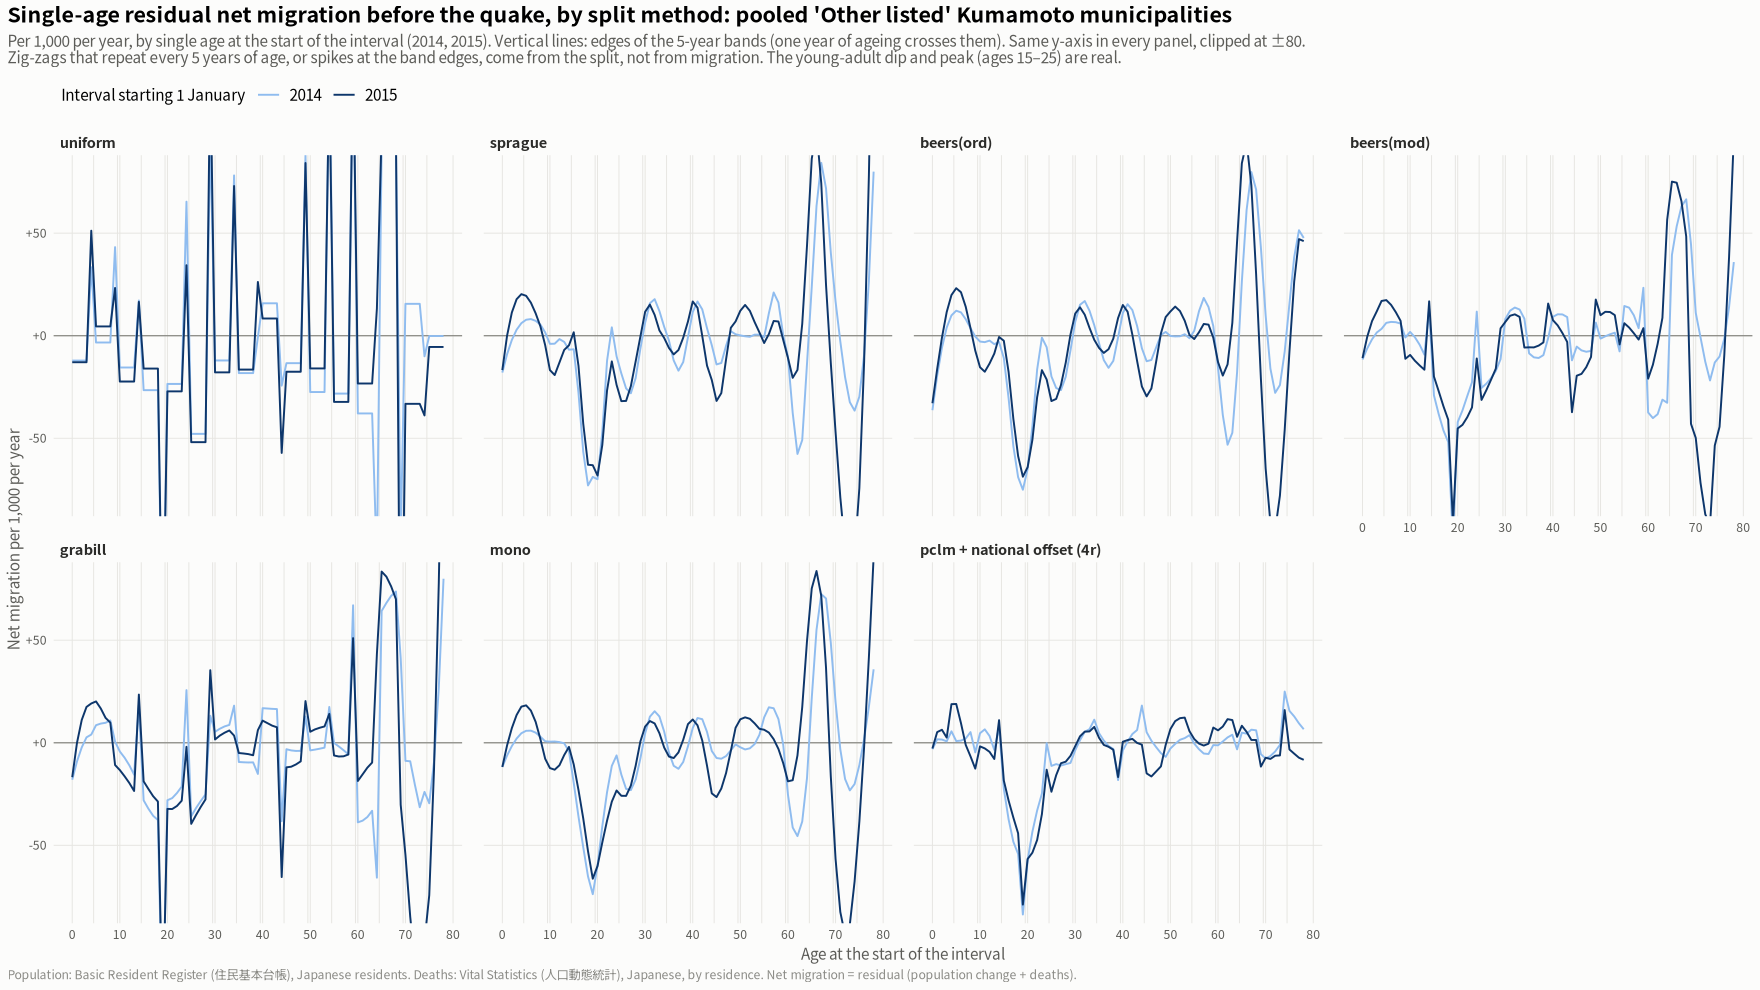

In [7]:
sa <- res |> filter(group == group_levels[3], start %in% 2014:2015) |>
  group_by(method, start, age) |> summarise(rate = 1000 * sum(NM) / sum(P0), .groups = "drop")
p3 <- ggplot(sa, aes(age, rate, colour = factor(start))) +
  geom_vline(xintercept = seq(4.5, 74.5, 5), colour = grid_col, linewidth = 0.3) +
  geom_hline(yintercept = 0, colour = ink3, linewidth = 0.4) +
  geom_line(linewidth = 0.6) +
  facet_wrap(~method, ncol = 4) +
  scale_colour_manual(values = c(`2014` = "#8fbcef", `2015` = "#0d366b"), name = "Interval starting 1 January") +
  scale_x_continuous(breaks = seq(0, 80, 10)) +
  scale_y_continuous(labels = function(v) sprintf("%+g", v)) +
  coord_cartesian(ylim = c(-80, 80)) +
  labs(title = "Single-age residual net migration before the quake, by split method: pooled 'Other listed' Kumamoto municipalities",
       subtitle = paste0("Per 1,000 per year, by single age at the start of the interval (2014, 2015). Vertical lines: edges of the 5-year bands (one year of ageing crosses them). ",
                         "Same y-axis in every panel, clipped at ±80.\nZig-zags that repeat every 5 years of age, or spikes at the band edges, come from the split, not from migration. ",
                         "The young-adult dip and peak (ages 15–25) are real."),
       x = "Age at the start of the interval", y = "Net migration per 1,000 per year", caption = src_note) +
  base_theme() + theme(panel.grid.major.x = element_line(colour = grid_col, linewidth = 0.3))
show_save(p3, "03_single_age_residual_by_method", width = 18, height = 8.5)

## 4. Validation against reported net migration, Kumamoto 2014–2020

As 4r figure 6 and 5r figures 3 and 11. Cells are municipality × baseline cohort bin × calendar year, per 1,000 per year. The reported side, (in − out) Japanese movers between municipalities with the 1D pclm split from 4r and the same Lexis rule, is identical for every method; only the population and death splits differ. Ages 79+ at the start of an interval are left out for every method, so the 4r numbers here differ slightly from 4r and 5r.

In [8]:
M1 <- fits1d |> filter(series %in% c("in", "out"), year %in% death_years) |>
  select(code, year, series, age, M = fit) |>
  group_by(code, year, series) |> arrange(age, .by_group = TRUE) |>
  mutate(Mc = 0.5 * (M + lead(M, default = 0))) |> ungroup() |>
  select(-M) |> pivot_wider(names_from = series, values_from = Mc)
val <- res |> filter(!is.na(cohort)) |>
  inner_join(M1 |> rename(start = year), by = c("code", "start", "age")) |>
  group_by(method, code, short, group, cohort, start) |>
  summarise(P0 = sum(P0), NM = sum(NM), rep = sum(`in`) - sum(out), .groups = "drop") |>
  mutate(residual = 1000 * NM / P0, reported = 1000 * rep / P0, gap = residual - reported)
munipop <- pop5 |> filter(year == base) |> group_by(code) |> summarise(pop2016 = sum(n), .groups = "drop")
val <- val |> left_join(munipop, by = "code") |>
  mutate(size = cut(pop2016, c(0, 5000, 10000, 20000, 50000, 1e7),
                    labels = c("< 5k", "5–10k", "10–20k", "20–50k", "≥ 50k")))

# Summary per method and group (as the 4r section 6 table), plus share of cells within +-5 / +-10 per 1,000
val |> group_by(group, method) |>
  summarise(cells = n(), correlation = round(cor(residual, reported), 3),
            sd_gap = round(sd(gap), 1),
            mean_difference = round(weighted.mean(gap, P0), 1),
            within_5 = round(mean(abs(gap) <= 5), 2), within_10 = round(mean(abs(gap) <= 10), 2), .groups = "drop") |>
  as.data.frame()

group,method,cells,correlation,sd_gap,mean_difference,within_5,within_10
<fct>,<fct>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
High damage (全壊率 ≥ 1),uniform,420,0.720,28.0,0.7,0.24,0.40
High damage (全壊率 ≥ 1),sprague,420,0.727,29.1,1.7,0.20,0.38
High damage (全壊率 ≥ 1),beers(ord),420,0.747,27.2,0.3,0.21,0.39
High damage (全壊率 ≥ 1),beers(mod),420,0.751,26.9,0.8,0.21,0.38
High damage (全壊率 ≥ 1),grabill,420,0.718,29.2,1.7,0.21,0.42
High damage (全壊率 ≥ 1),mono,420,0.747,27.4,0.7,0.21,0.38
High damage (全壊率 ≥ 1),pclm + national offset (4r),420,0.824,21.3,0.1,0.24,0.48
熊本市,uniform,84,0.192,14.2,0.9,0.58,0.73
熊本市,sprague,84,0.177,18.3,0.9,0.44,0.68


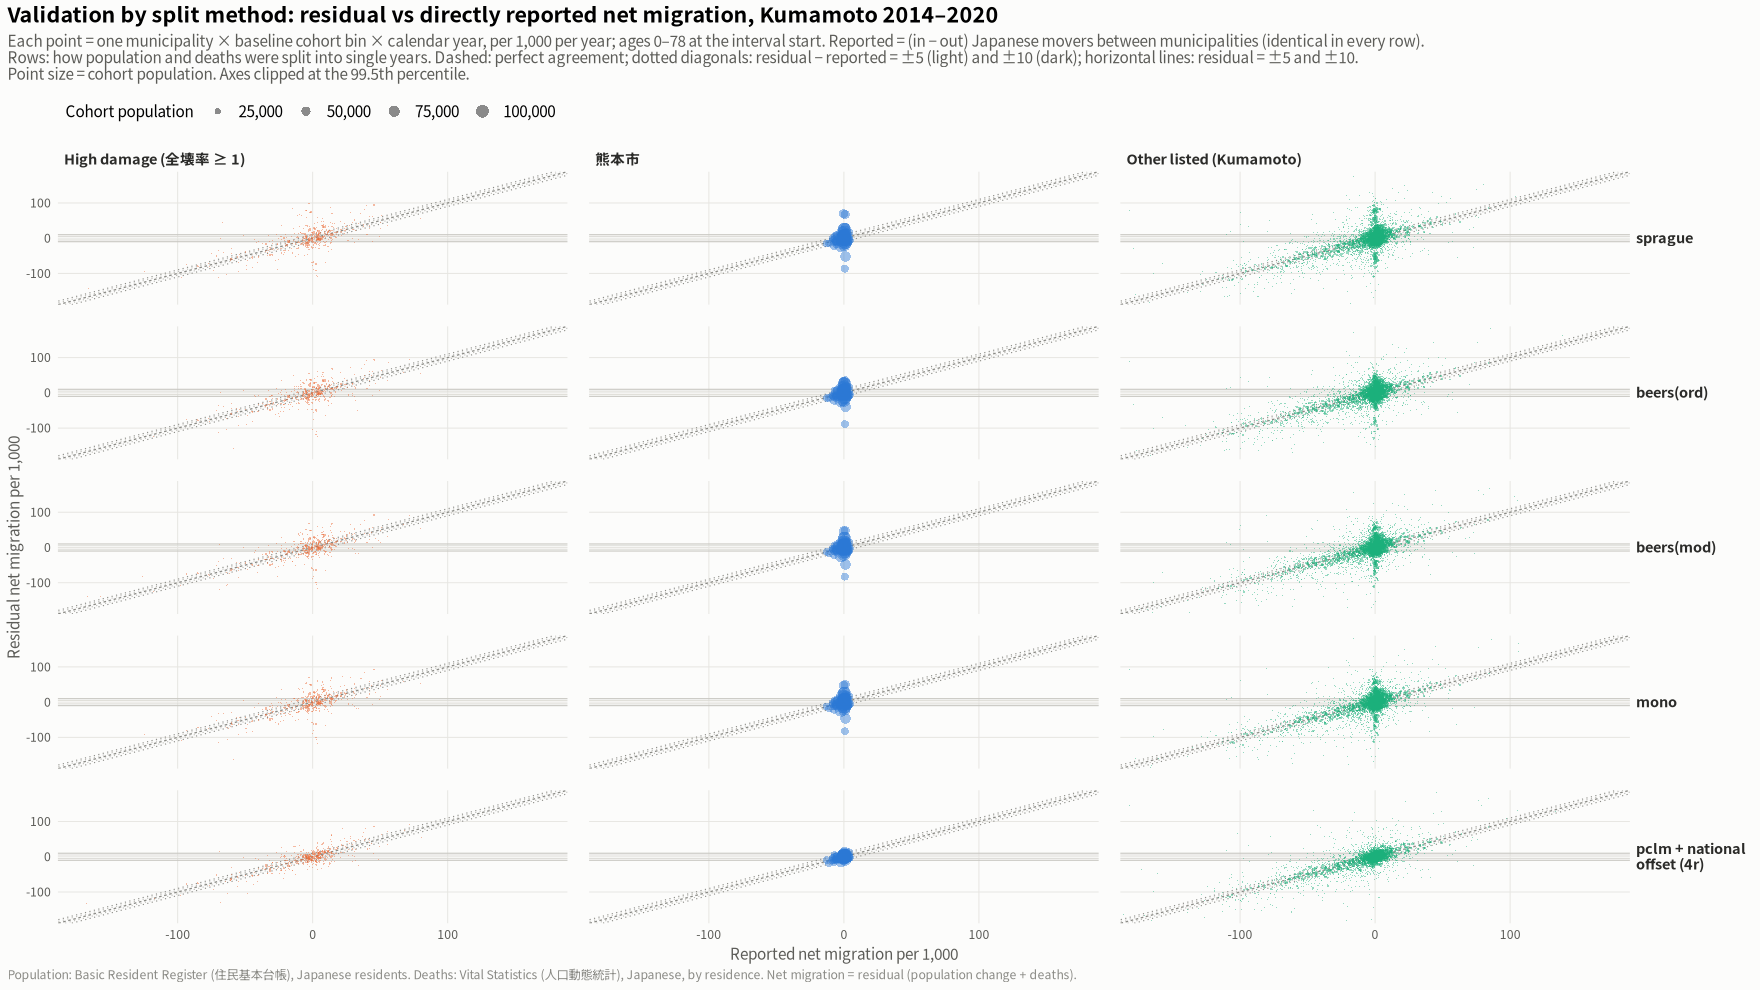

In [9]:
# Figure 4: residual vs reported, one row per method (uniform and grabill left to the summary figure)
scatter_methods <- c("sprague", "beers(ord)", "beers(mod)", "mono", ref_lab)
v4 <- val |> filter(method %in% scatter_methods) |> mutate(method = factor(method, levels = scatter_methods))
lim <- quantile(abs(c(v4$residual, v4$reported)), 0.995)
p4 <- ggplot(v4, aes(reported, residual, colour = group)) +
  geom_hline(yintercept = c(-10, 10), colour = "#c9c8c3", linewidth = 0.35) +
  geom_hline(yintercept = c(-5, 5), colour = "#dcdbd6", linewidth = 0.3) +
  geom_abline(slope = 1, intercept = c(-10, 10), colour = "#8a8a85", linewidth = 0.35, linetype = "dotted") +
  geom_abline(slope = 1, intercept = c(-5, 5), colour = "#b5b4af", linewidth = 0.3, linetype = "dotted") +
  geom_abline(slope = 1, intercept = 0, colour = ink3, linewidth = 0.4, linetype = "22") +
  geom_point(aes(size = P0), alpha = 0.45, stroke = 0) +
  facet_grid(method ~ group, labeller = labeller(method = label_wrap_gen(16))) +
  scale_colour_manual(values = group_cols, guide = "none") +
  scale_size_area(max_size = 4, name = "Cohort population", labels = scales::label_comma()) +
  coord_cartesian(xlim = c(-lim, lim), ylim = c(-lim, lim)) +
  labs(title = "Validation by split method: residual vs directly reported net migration, Kumamoto 2014–2020",
       subtitle = paste0("Each point = one municipality × baseline cohort bin × calendar year, per 1,000 per year; ages 0–78 at the interval start. ",
                         "Reported = (in − out) Japanese movers between municipalities (identical in every row).\n",
                         "Rows: how population and deaths were split into single years. Dashed: perfect agreement; dotted diagonals: residual − reported = ±5 (light) and ±10 (dark); ",
                         "horizontal lines: residual = ±5 and ±10.\nPoint size = cohort population. Axes clipped at the 99.5th percentile."),
       x = "Reported net migration per 1,000", y = "Residual net migration per 1,000", caption = src_note) +
  base_theme() +
  theme(panel.grid.major.x = element_line(colour = grid_col, linewidth = 0.3),
        strip.text.y = element_text(angle = 0, hjust = 0))
show_save(p4, "04_residual_vs_reported_by_method", width = 16, height = 21)

### Figure 5: how far the residual is from reported, by cohort and municipality size

The SD of residual − reported over the cells of figure 4, for all seven splits. Lower is closer to the reported migration.

SD of residual - reported by cohort bin (per 1,000):


cohort,uniform,sprague,beers(ord),beers(mod),grabill,mono,pclm + national offset (4r)
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
0–4,42.0,64.1,52.1,53.3,64.7,55.3,40.1
5–9,23.9,28.4,27.4,26.2,28.2,27.5,24.9
10–14,34.1,35.6,35.2,34.1,33.9,34.9,33.5
15–19,38.4,39.2,38.8,38.0,37.6,38.9,36.8
20–24,42.0,40.5,40.3,40.1,39.7,40.8,39.7
25–29,34.0,36.1,35.6,34.1,33.0,35.8,32.6
30–34,27.9,33.4,32.9,31.5,28.9,33.9,28.7
35–39,27.0,29.5,29.3,28.5,27.1,29.8,28.1
40–49,15.5,15.8,15.7,15.5,14.9,15.9,14.6


By municipality size:


size,uniform,sprague,beers(ord),beers(mod),grabill,mono,pclm + national offset (4r)
<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
< 5k,52.7,64.8,58.5,59.1,63.5,61.0,51.4
5–10k,32.7,35.9,33.6,32.9,34.7,34.1,28.4
10–20k,26.8,30.3,28.4,26.9,29.6,27.9,21.9
20–50k,19.6,21.9,19.9,19.2,22.2,19.7,12.9
≥ 50k,17.5,19.7,17.2,17.1,20.3,17.3,8.7


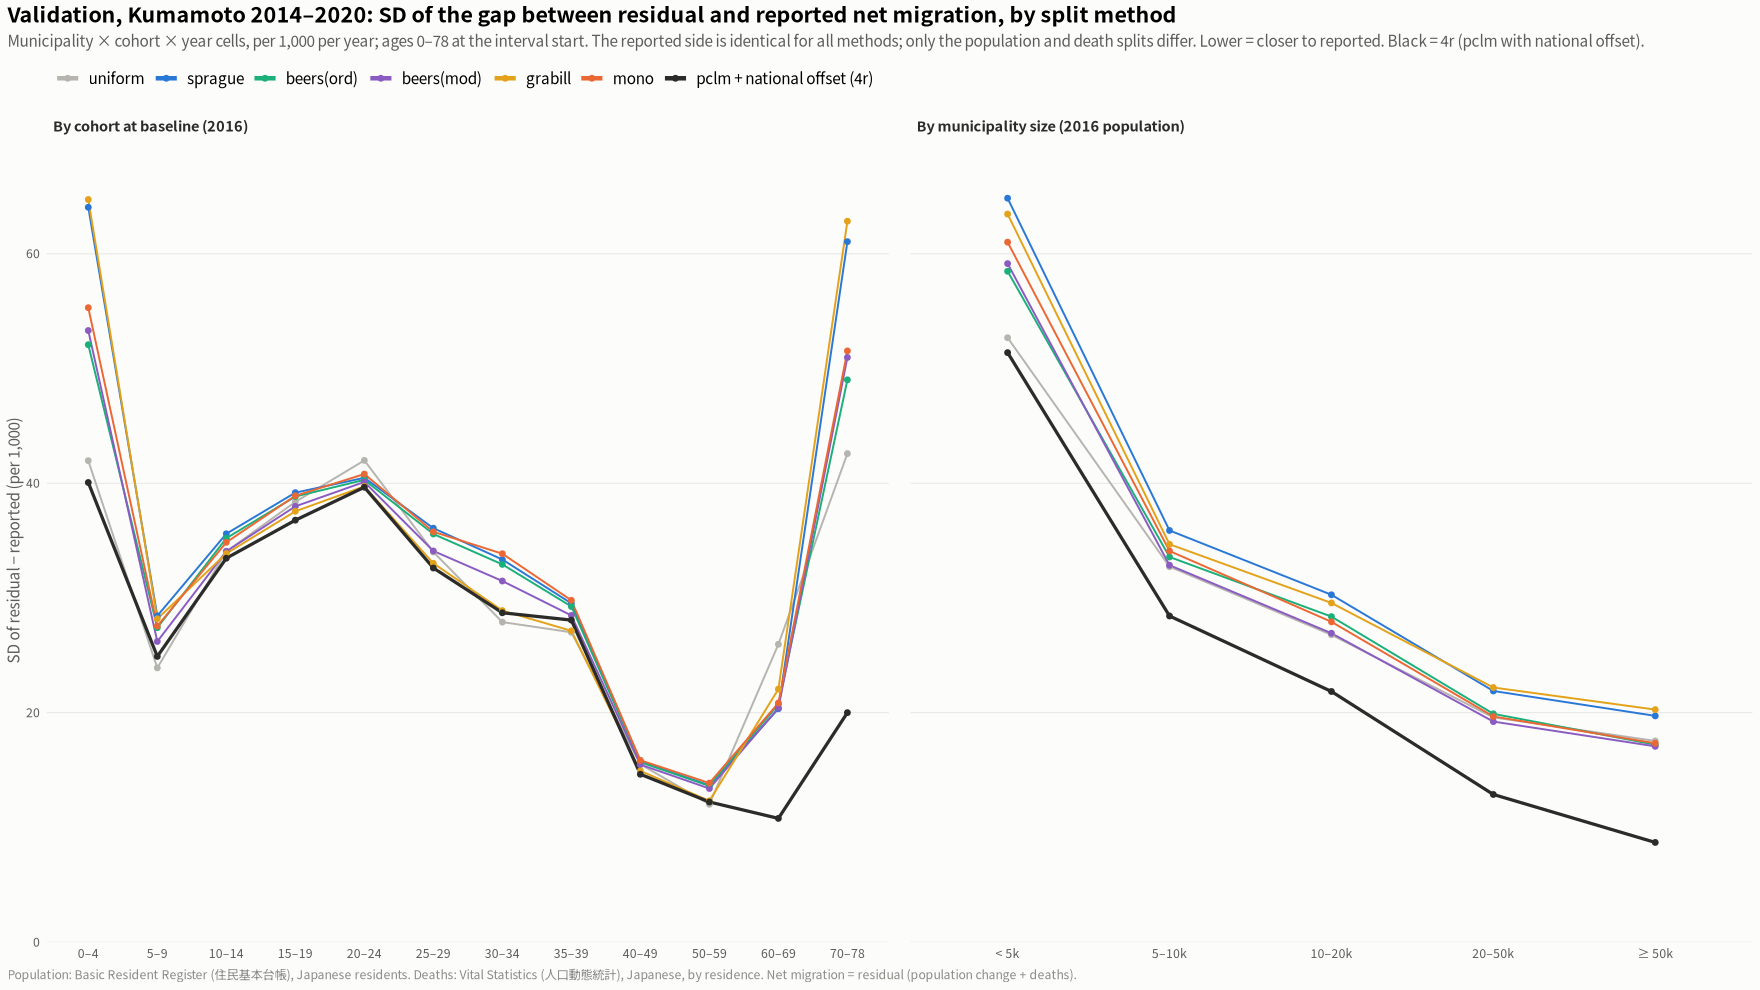

In [10]:
cat("SD of residual - reported by cohort bin (per 1,000):\n")
val |> group_by(cohort, method) |> summarise(sd_gap = round(sd(gap), 1), .groups = "drop") |>
  pivot_wider(names_from = method, values_from = sd_gap) |> as.data.frame()
cat("By municipality size:\n")
val |> group_by(size, method) |> summarise(sd_gap = round(sd(gap), 1), .groups = "drop") |>
  pivot_wider(names_from = method, values_from = sd_gap) |> as.data.frame()

vs <- bind_rows(
  val |> group_by(method, x = cohort) |> summarise(sd_gap = sd(gap), .groups = "drop") |> mutate(panel = "By cohort at baseline (2016)"),
  val |> group_by(method, x = size) |> summarise(sd_gap = sd(gap), .groups = "drop") |> mutate(panel = "By municipality size (2016 population)")) |>
  mutate(x = factor(x, levels = c(cohort_bins, "< 5k", "5–10k", "10–20k", "20–50k", "≥ 50k")))
p5 <- ggplot(vs, aes(x, sd_gap, colour = method, group = method)) +
  geom_line(aes(linewidth = method == ref_lab)) + geom_point(size = 1.5) +
  facet_wrap(~panel, scales = "free_x") +
  scale_colour_manual(values = method_cols, name = NULL) +
  scale_linewidth_manual(values = c(`FALSE` = 0.6, `TRUE` = 1), guide = "none") +
  scale_y_continuous(limits = c(0, NA), expand = expansion(mult = c(0, 0.08))) +
  labs(title = "Validation, Kumamoto 2014–2020: SD of the gap between residual and reported net migration, by split method",
       subtitle = paste0("Municipality × cohort × year cells, per 1,000 per year; ages 0–78 at the interval start. The reported side is identical for all methods; ",
                         "only the population and death splits differ. Lower = closer to reported. Black = 4r (pclm with national offset)."),
       x = NULL, y = "SD of residual − reported (per 1,000)", caption = src_note) +
  base_theme() +
  guides(colour = guide_legend(nrow = 1, override.aes = list(linewidth = 1.4)))
show_save(p5, "05_validation_sd_by_method", width = 16, height = 6.5)